### Start Spark Session

In [36]:

# 1. IMPORTS
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# 2. SETUP VISUALIZATION STYLE
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# 3. START SPARK SESSION
spark = SparkSession.builder \
    .appName("EventStudyCARAnalysis") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "100") \
    .getOrCreate()

print(" Spark session created!")
print(f" Spark version: {spark.version}")


 Spark session created!
 Spark version: 4.0.1


### Load the Parquet file with our basetable 


In [37]:
parquet_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"  
df = spark.read.parquet(parquet_path)
df.printSchema()

root
 |-- industry: string (nullable = true)
 |-- biweekly_period: string (nullable = true)
 |-- biweekly_index: integer (nullable = true)
 |-- ticker: string (nullable = true)
 |-- longname: string (nullable = true)
 |-- benchmark: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- benchmark_period_return: double (nullable = true)
 |-- beta: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_intraday_range: double (nullable = true)
 |-- total_volume: double (nullable = true)
 |-- avg_daily_volume: double (nullable = true)
 |-- max_daily_volume:

### Check the Data Structure 

In [38]:
# Check column names
print("Column names in your data:")
for col in df.columns:
    print(f"  - {col}")

# Check data types
print("\n Data types:")
for field in df.schema.fields:
    print(f"  - {field.name}: {field.dataType}")

# Check for nulls
print("\n Checking for null values:")
for col in df.columns:
    null_count = df.filter(F.col(col).isNull()).count()
    print(f"  - {col}: {null_count:,} nulls")

Column names in your data:
  - industry
  - biweekly_period
  - biweekly_index
  - ticker
  - longname
  - benchmark
  - period_start
  - period_end
  - period_open
  - period_close
  - period_high
  - period_low
  - avg_close
  - period_return
  - benchmark_period_return
  - beta
  - price_volatility
  - return_volatility
  - avg_intraday_range
  - max_intraday_range
  - total_volume
  - avg_daily_volume
  - max_daily_volume
  - volume_volatility
  - avg_volume_up_days
  - avg_volume_down_days
  - gap_count
  - avg_gap_size
  - max_gap
  - up_days
  - down_days
  - financing_next_period
  - has_property_acquisition
  - has_exploration_results
  - maturity
  - avg_prChg
  - price_deviation_from_year
  - has_financing
  - prev_period_return
  - prev_price_volatility
  - prev_avg_daily_volume
  - prev_volume_volatility
  - prev_gap_count
  - prev_exploration_results
  - prev_property_acquisition
  - current_financing_announcement
  - prev_financing_announcement
  - second_prev_financing_

In [39]:
# ============================================================================
# STEP 1: CALCULATE ABNORMAL RETURNS
# ============================================================================

# Calculate abnormal returns (period return - benchmark return)
df_abnormal = df.withColumn(
    "abnormal_return",
    F.col("period_return") - F.col("benchmark_period_return")
)

# Show sample of data with abnormal returns
df_abnormal.select(
    "ticker", 
    "biweekly_period", 
    "period_return", 
    "benchmark_period_return", 
    "abnormal_return",
    "current_financing_announcement"
).limit(5).show()

+------+---------------+--------------------+-----------------------+--------------------+------------------------------+
|ticker|biweekly_period|       period_return|benchmark_period_return|     abnormal_return|current_financing_announcement|
+------+---------------+--------------------+-----------------------+--------------------+------------------------------+
|ARG.TO|             P0|0.015503875968992276|   -0.00862805917278...| 0.02413193514177514|                             0|
|ARG.TO|             P1|-0.03846153846153855|   -0.03921038665635357|7.488481948150216E-4|                             0|
|ARG.TO|             P2|0.016260162601626105|   -5.74208399441555...| 0.01683437100106766|                             0|
|ARG.TO|             P3|-0.00729927007299...|   -0.00166482243363...|-0.00563444763935...|                             0|
|ARG.TO|             P4| 0.04166666666666674|   0.012845387588632295|0.028821279078034445|                             0|
+------+---------------+

In [40]:
# ============================================================================
# STEP 2: CREATE EVENT WINDOWS
# ============================================================================

# Get unique industries
industries = df_abnormal.select("industry").distinct().rdd.flatMap(lambda x: x).collect()
print(f"Industries found: {len(industries)}")

# Create unique identifier
df_with_index = df_abnormal.withColumn(
    "row_id",
    F.monotonically_increasing_id()
)

# Get all financing events
financing_events = df_with_index.filter(
    F.col("current_financing_announcement") == 1
)

print(f"Total financing events: {financing_events.count():,}")

# Show financing events by industry
financing_events.groupBy("industry").count().orderBy(F.desc("count")).show()

Industries found: 5
Total financing events: 33
+--------------------+-----+
|            industry|count|
+--------------------+-----+
|                Gold|   12|
|Other Precious Me...|    8|
|Other Industrial ...|    7|
|              Silver|    4|
|              Copper|    2|
+--------------------+-----+



In [41]:
# ============================================================================
# STEP 3: EVENT STUDY APPROACH
# ============================================================================

# Get financing events
financing_events = df_abnormal.filter(
    F.col("current_financing_announcement") == 1
).select(
    "ticker",
    "biweekly_index",
    "industry",
    "abnormal_return"
).withColumnRenamed("biweekly_index", "event_index") \
 .withColumnRenamed("industry", "event_industry") \
 .withColumnRenamed("abnormal_return", "event_abnormal_return")

print(f"Financing events: {financing_events.count():,}")

# Get all periods
all_periods = df_abnormal.select(
    "ticker",
    "biweekly_index",
    "industry",
    "abnormal_return",
    "period_return",
    "benchmark_period_return"
)

# Create relative periods (-4 to +4)
relative_periods_df = spark.createDataFrame(
    [(-4,), (-3,), (-2,), (-1,), (0,), (1,), (2,), (3,), (4,)],
    ["relative_period"]
)

# Create event windows
event_windows = financing_events.alias("events").join(
    relative_periods_df,
    how="cross"
).join(
    all_periods.alias("periods"),
    (F.col("events.ticker") == F.col("periods.ticker")) &
    (F.col("periods.biweekly_index") == F.col("events.event_index") + F.col("relative_period")),
    "inner"
).select(
    F.col("events.ticker").alias("event_ticker"),
    F.col("events.event_index"),
    F.col("events.event_industry"),
    F.col("relative_period"),
    F.col("periods.abnormal_return").alias("period_abnormal_return"),
    F.col("periods.period_return"),
    F.col("periods.benchmark_period_return")
)

print(f"Event windows: {event_windows.count():,} rows")

# Show sample
first_events = event_windows.select("event_ticker", "event_index").distinct().limit(3)

for row in first_events.collect():
    ticker = row["event_ticker"]
    event_idx = row["event_index"]
    print(f"\nSample event: {ticker} at index {event_idx}")
    event_windows.filter(
        (F.col("event_ticker") == ticker) & 
        (F.col("event_index") == event_idx)
    ).orderBy("relative_period").show()

Financing events: 33
Event windows: 275 rows

Sample event: FNM.V at index 23
+------------+-----------+--------------------+---------------+----------------------+--------------------+-----------------------+
|event_ticker|event_index|      event_industry|relative_period|period_abnormal_return|       period_return|benchmark_period_return|
+------------+-----------+--------------------+---------------+----------------------+--------------------+-----------------------+
|       FNM.V|         23|Other Precious Me...|             -4|   0.02550295044701001|0.014285714285714235|   -0.01121723616129...|
|       FNM.V|         23|Other Precious Me...|             -3|   -0.0890394929790087|-0.09589041095890405|   -0.00685091797989...|
|       FNM.V|         23|Other Precious Me...|             -2|  -0.00220102125754...|                 0.0|   0.002201021257547...|
|       FNM.V|         23|Other Precious Me...|             -1|  -0.03672814543536...|-0.03875968992248069|   -0.00203154448711...

In [42]:
# ============================================================================
# STEP 4: CALCULATE CUMULATIVE ABNORMAL RETURNS (CAR)
# ============================================================================

print(f"Total rows in event_windows: {event_windows.count():,}")

# Count events by industry
event_windows.groupBy("event_industry").agg(
    F.countDistinct("event_ticker", "event_index").alias("n_events")
).orderBy(F.desc("n_events")).show()

# Check for complete event windows
events_completeness = event_windows.groupBy("event_ticker", "event_index").agg(
    F.count("*").alias("n_periods"),
    F.collect_set("relative_period").alias("periods_present")
)

print(f"Total unique events: {events_completeness.count():,}")

# Filter to events with complete windows (all 9 periods)
complete_events = events_completeness.filter(F.col("n_periods") == 9)
print(f"Events with complete windows (9 periods): {complete_events.count():,}")

# Get list of complete event keys
complete_event_keys = complete_events.select("event_ticker", "event_index")

# Filter event_windows to only include complete events
event_windows_complete = event_windows.join(
    complete_event_keys,
    ["event_ticker", "event_index"],
    "inner"
)

print(f"Rows after filtering to complete events: {event_windows_complete.count():,}")

# Calculate Cumulative Abnormal Returns (CAR)
window_spec = Window.partitionBy("event_ticker", "event_index") \
                   .orderBy("relative_period")

event_study_car = event_windows_complete.withColumn(
    "car",
    F.sum("period_abnormal_return").over(window_spec)
)

# Calculate cumulative period return and benchmark return for comparison
event_study_car = event_study_car.withColumn(
    "cum_period_return",
    F.sum("period_return").over(window_spec)
).withColumn(
    "cum_benchmark_return",
    F.sum("benchmark_period_return").over(window_spec)
)

# Show sample CAR calculation
first_event = event_study_car.select("event_ticker", "event_index").first()
if first_event:
    sample_ticker = first_event["event_ticker"]
    sample_index = first_event["event_index"]
    
    print(f"\nSample event: {sample_ticker} at index {sample_index}")
    
    event_study_car.filter(
        (F.col("event_ticker") == sample_ticker) & 
        (F.col("event_index") == sample_index)
    ).orderBy("relative_period").select(
        "relative_period",
        "period_abnormal_return",
        "car",
        "period_return",
        "benchmark_period_return"
    ).show()

Total rows in event_windows: 275
+--------------------+--------+
|      event_industry|n_events|
+--------------------+--------+
|                Gold|      12|
|Other Precious Me...|       8|
|Other Industrial ...|       7|
|              Silver|       4|
|              Copper|       2|
+--------------------+--------+

Total unique events: 33
Events with complete windows (9 periods): 24
Rows after filtering to complete events: 216

Sample event: FNM.V at index 23
+---------------+----------------------+--------------------+--------------------+-----------------------+
|relative_period|period_abnormal_return|                 car|       period_return|benchmark_period_return|
+---------------+----------------------+--------------------+--------------------+-----------------------+
|             -4|   0.02550295044701001| 0.02550295044701001|0.014285714285714235|   -0.01121723616129...|
|             -3|   -0.0890394929790087| -0.0635365425319987|-0.09589041095890405|   -0.00685091797989.

Events per industry:
                                  n_events  n_observations
event_industry                                            
Gold                                   8.0              72
Other Industrial Metals & Mining       6.0              54
Other Precious Metals & Mining         5.0              45
Silver                                 3.0              27
Copper                                 2.0              18


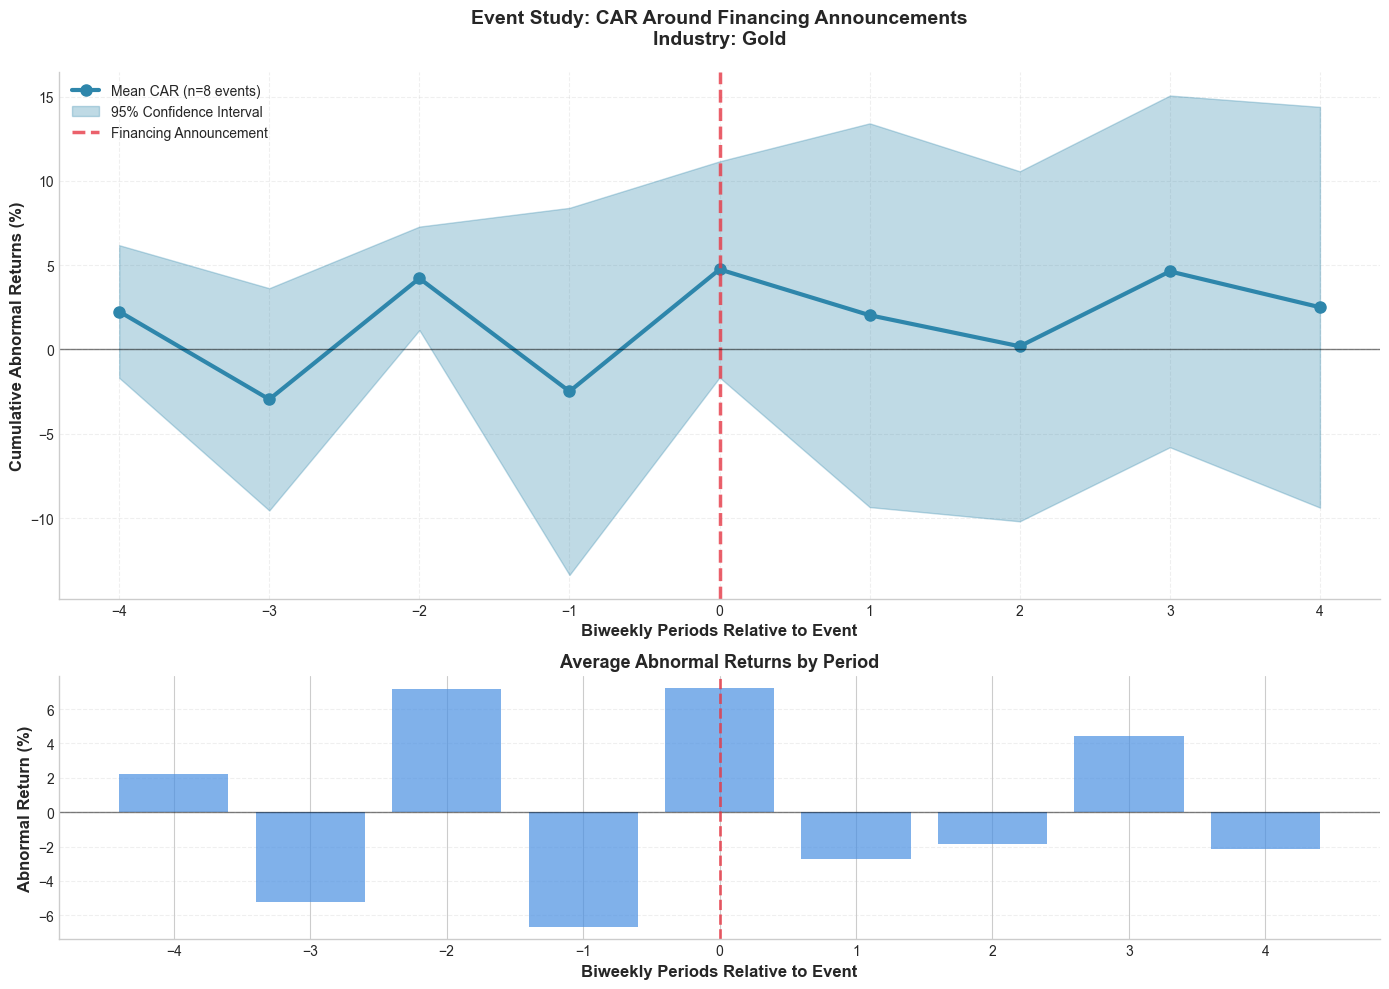


Industry: Gold (8 events)
  Pre-event CAR (-4 to -1): 0.25%
  Post-event CAR (0 to +4): 2.82%


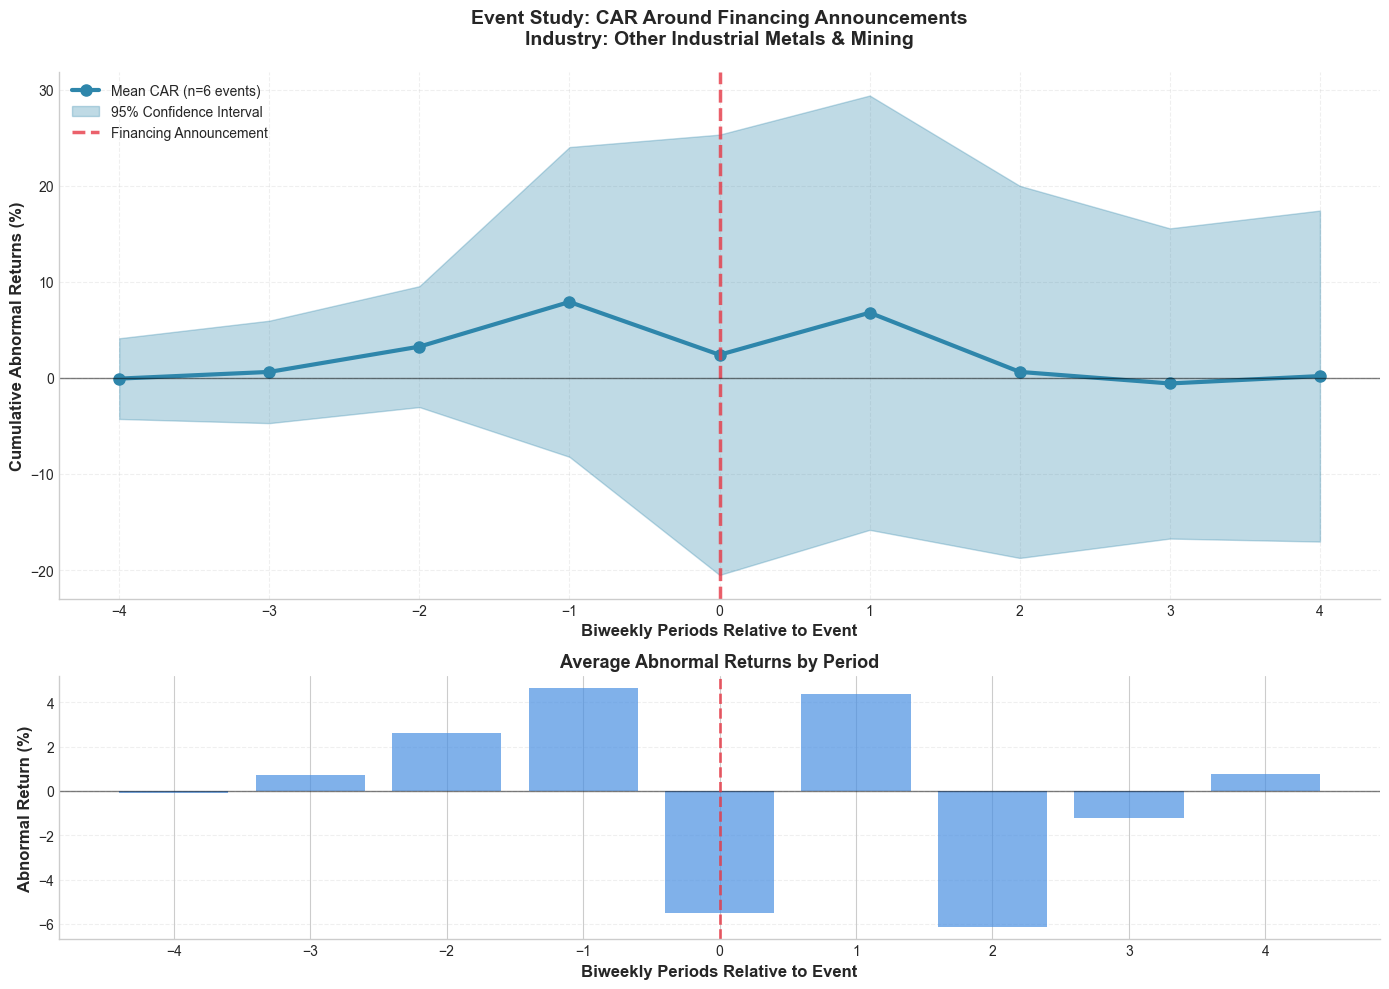


Industry: Other Industrial Metals & Mining (6 events)
  Pre-event CAR (-4 to -1): 2.93%
  Post-event CAR (0 to +4): 1.89%


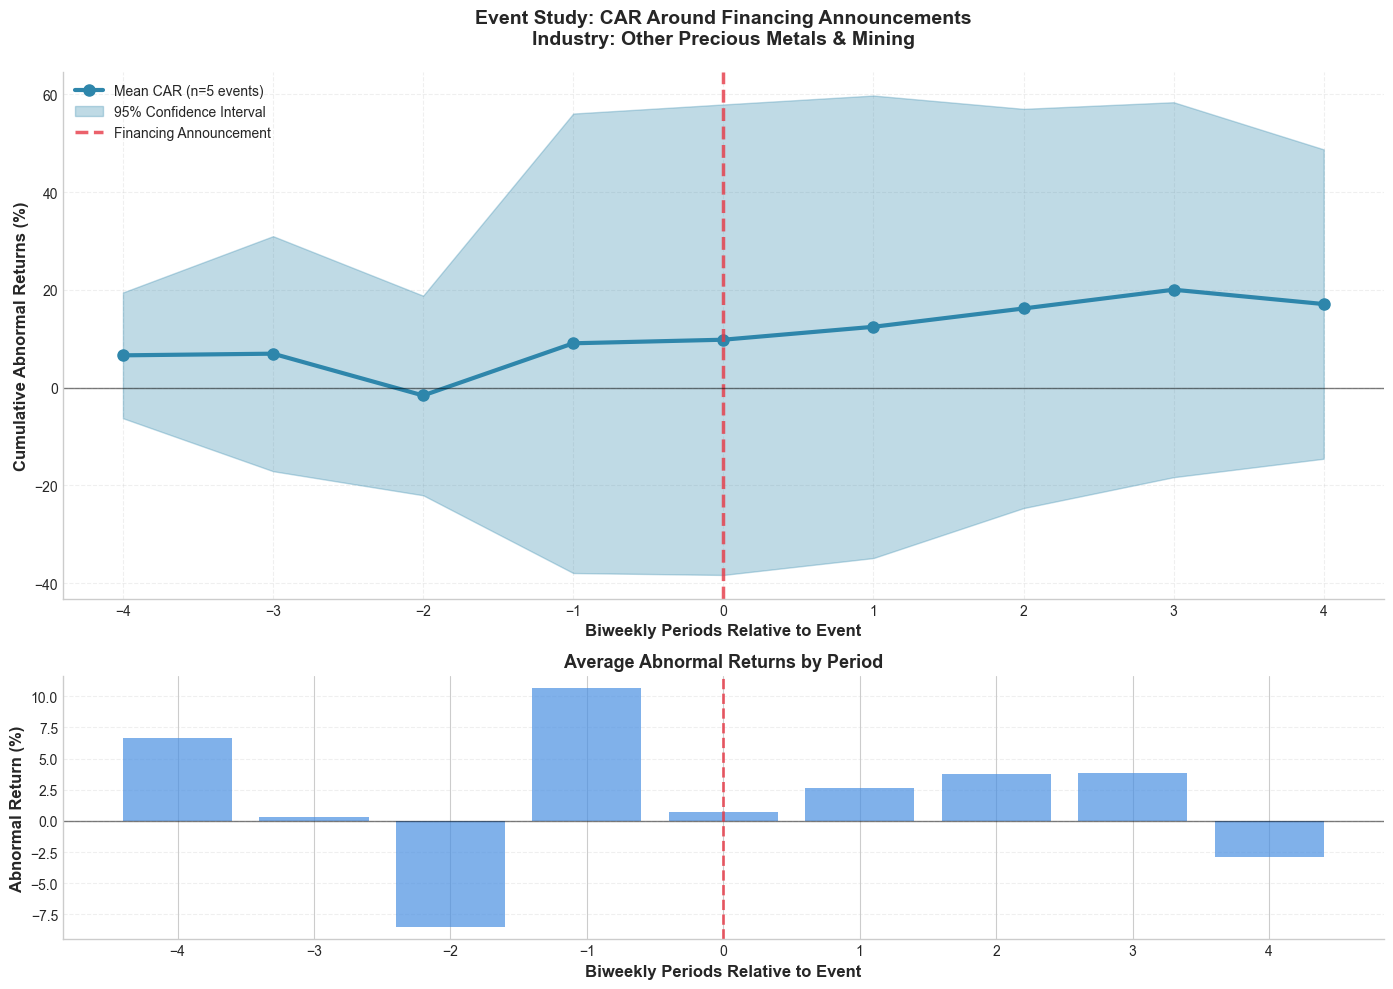


Industry: Other Precious Metals & Mining (5 events)
  Pre-event CAR (-4 to -1): 5.26%
  Post-event CAR (0 to +4): 15.11%


In [43]:
# ============================================================================
# STEP 5: AGGREGATE BY INDUSTRY AND CREATE PLOT (cutoff if less than 5 events)
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import seaborn as sns

# Aggregate statistics by industry and relative period
agg_by_industry = event_study_car.groupBy("event_industry", "relative_period").agg(
    F.avg("car").alias("mean_car"),
    F.stddev("car").alias("std_car"),
    F.count("*").alias("n_observations"),
    F.countDistinct("event_ticker", "event_index").alias("n_events"),
    F.avg("period_abnormal_return").alias("mean_abnormal_return"),
    F.avg("cum_period_return").alias("mean_cum_period_return"),
    F.avg("cum_benchmark_return").alias("mean_cum_benchmark_return")
).orderBy("event_industry", "relative_period")

# Convert to pandas for plotting
agg_pdf = agg_by_industry.toPandas()

# Show events per industry
industry_summary = agg_pdf.groupby("event_industry").agg({
    "n_events": "mean",
    "n_observations": "sum"
}).round(0).sort_values("n_events", ascending=False)
print("Events per industry:")
print(industry_summary)

# Set up plotting
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Get industries sorted by number of events
industries_in_data = agg_pdf.groupby("event_industry")["n_events"].mean() \
                           .sort_values(ascending=False).index.tolist()

# Create a plot for each industry
for industry in industries_in_data:
    # Filter data for this industry
    industry_data = agg_pdf[agg_pdf['event_industry'] == industry].copy()
    industry_data = industry_data.sort_values('relative_period')
    
    # Check data completeness
    if len(industry_data) < 9:
        continue
    
    n_events = int(industry_data['n_events'].mean())
    if n_events < 5:
        continue
    
    # Calculate confidence intervals (95%)
    t_critical = stats.t.ppf(0.975, n_events-1) if n_events > 1 else 1.96
    industry_data['ci_lower'] = industry_data['mean_car'] - t_critical * (industry_data['std_car'] / np.sqrt(industry_data['n_observations']))
    industry_data['ci_upper'] = industry_data['mean_car'] + t_critical * (industry_data['std_car'] / np.sqrt(industry_data['n_observations']))
    
    # Create the plot
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})
    
    # PLOT 1: Cumulative Abnormal Returns (CAR)
    ax1.plot(industry_data['relative_period'], industry_data['mean_car'] * 100,
            linewidth=3, color='#2E86AB', marker='o', markersize=8,
            label=f'Mean CAR (n={n_events} events)')
    
    ax1.fill_between(industry_data['relative_period'],
                    industry_data['ci_lower'] * 100,
                    industry_data['ci_upper'] * 100,
                    alpha=0.3, color='#2E86AB',
                    label='95% Confidence Interval')
    
    ax1.axvline(x=0, color='#E63946', linestyle='--',
               linewidth=2.5, alpha=0.8, label='Financing Announcement')
    ax1.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
    
    ax1.set_xlabel('Biweekly Periods Relative to Event', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Cumulative Abnormal Returns (%)', fontsize=12, fontweight='bold')
    ax1.set_title(f'Event Study: CAR Around Financing Announcements\nIndustry: {industry}', 
                 fontsize=14, fontweight='bold', pad=20)
    
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.set_xticks(range(-4, 5))
    ax1.legend(loc='upper left', fontsize=10)
    
    # PLOT 2: Average Abnormal Returns by Period
    ax2.bar(industry_data['relative_period'], industry_data['mean_abnormal_return'] * 100,
           alpha=0.7, color='#4A90E2')
    
    ax2.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
    ax2.axvline(x=0, color='#E63946', linestyle='--', linewidth=2, alpha=0.8)
    
    ax2.set_xlabel('Biweekly Periods Relative to Event', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Abnormal Return (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Average Abnormal Returns by Period', fontsize=13, fontweight='bold')
    ax2.set_xticks(range(-4, 5))
    ax2.grid(True, alpha=0.3, linestyle='--', axis='y')
    
    # Clean up spines
    for ax in [ax1, ax2]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate and print summary statistics
    pre_event_mean = industry_data[industry_data['relative_period'] < 0]['mean_car'].mean() * 100
    post_event_mean = industry_data[industry_data['relative_period'] >= 0]['mean_car'].mean() * 100
    
    print(f"\nIndustry: {industry} ({n_events} events)")
    print(f"  Pre-event CAR (-4 to -1): {pre_event_mean:.2f}%")
    print(f"  Post-event CAR (0 to +4): {post_event_mean:.2f}%")

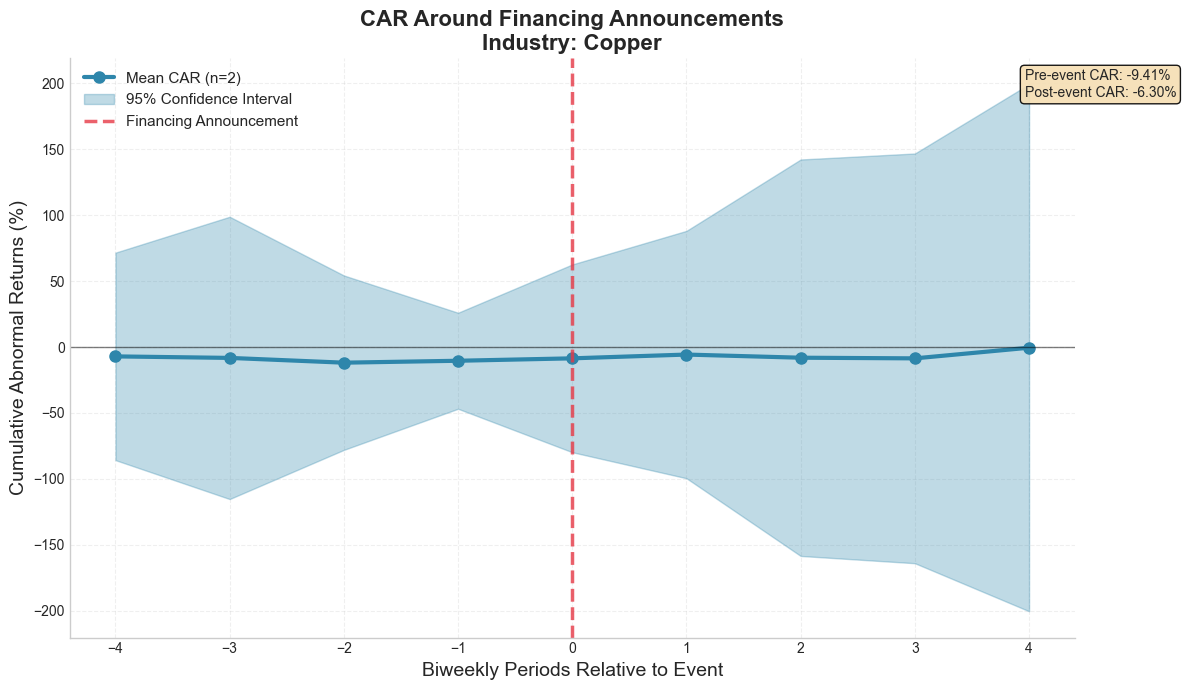

Industry: Copper (2 events)
  Pre-event CAR: -9.41%
  Post-event CAR: -6.30%


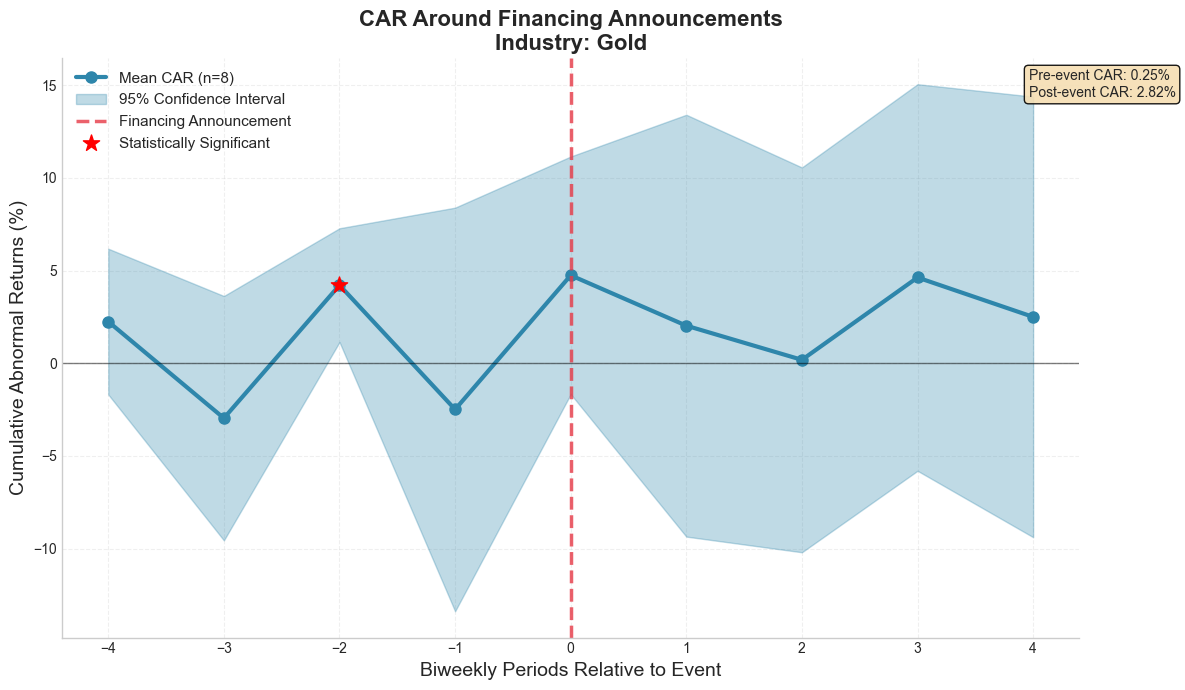

Industry: Gold (8 events)
  Pre-event CAR: 0.25%
  Post-event CAR: 2.82%


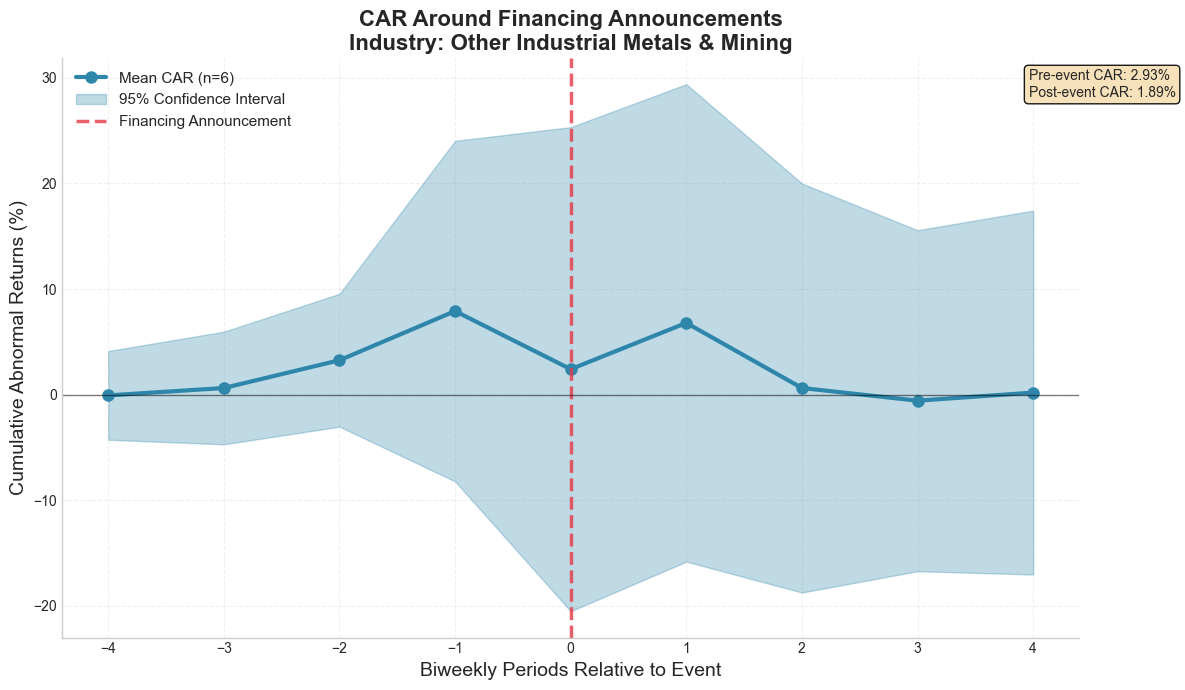

Industry: Other Industrial Metals & Mining (6 events)
  Pre-event CAR: 2.93%
  Post-event CAR: 1.89%


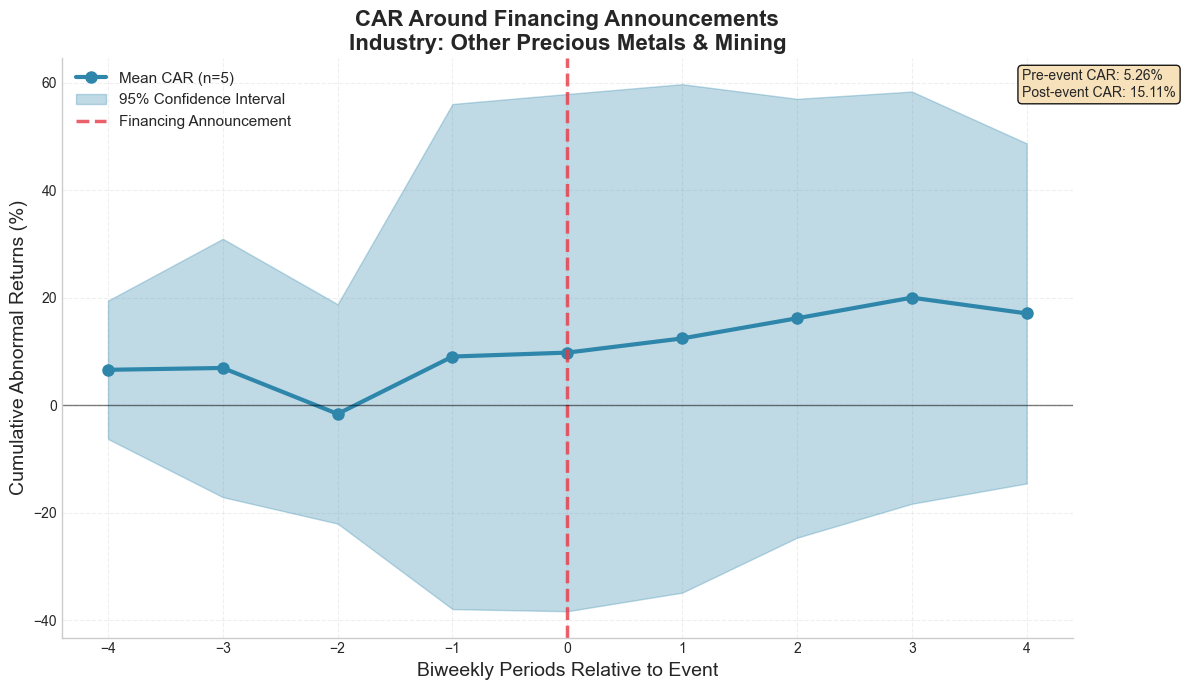

Industry: Other Precious Metals & Mining (5 events)
  Pre-event CAR: 5.26%
  Post-event CAR: 15.11%


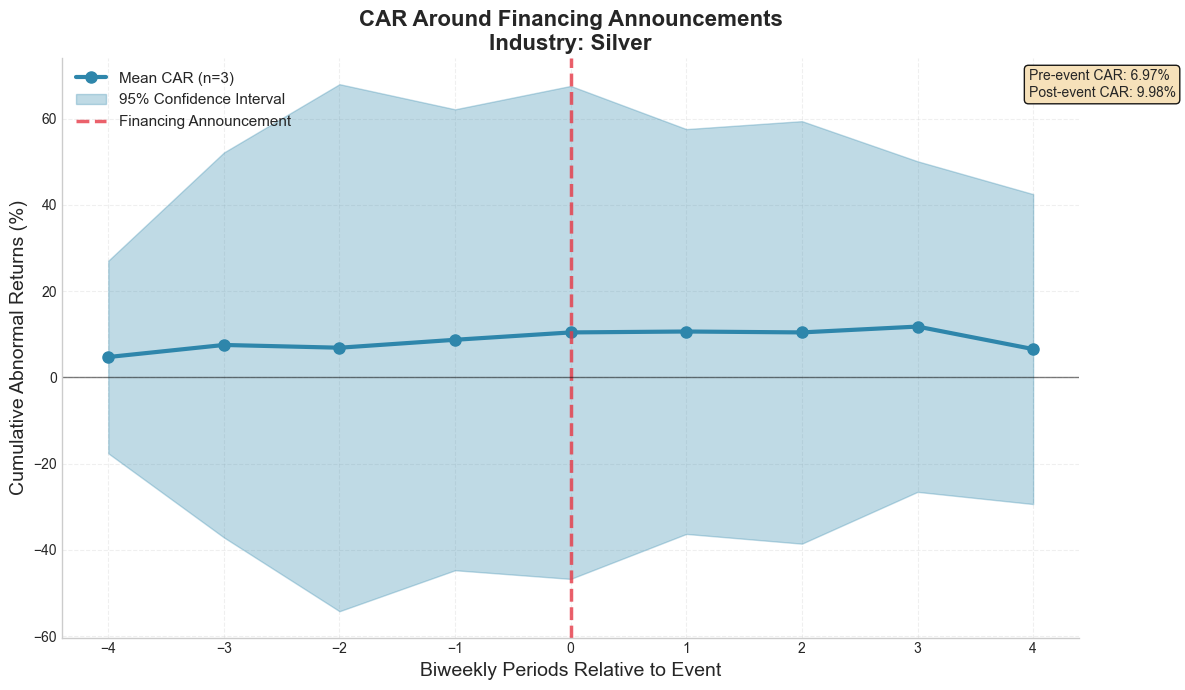

Industry: Silver (3 events)
  Pre-event CAR: 6.97%
  Post-event CAR: 9.98%


In [44]:
# ============================================================================
# CREATE CAR PLOTS FOR EACH INDUSTRY
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')

# Get unique industries
industries_in_data = sorted(agg_pdf['event_industry'].unique())

# Create a plot for each industry
for industry in industries_in_data:
    # Filter data for this industry
    industry_data = agg_pdf[agg_pdf['event_industry'] == industry].copy()
    industry_data = industry_data.sort_values('relative_period')
    
    if len(industry_data) < 9:
        continue
    
    # Calculate confidence intervals (95%)
    n = industry_data['n_events'].mean()
    t_critical = stats.t.ppf(0.975, n-1) if n > 1 else 1.96
    
    industry_data['ci_lower'] = industry_data['mean_car'] - t_critical * (industry_data['std_car'] / np.sqrt(industry_data['n_events']))
    industry_data['ci_upper'] = industry_data['mean_car'] + t_critical * (industry_data['std_car'] / np.sqrt(industry_data['n_events']))
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plot mean CAR
    ax.plot(industry_data['relative_period'], industry_data['mean_car'] * 100,
            linewidth=3, color='#2E86AB', marker='o', markersize=8,
            label=f'Mean CAR (n={int(n)})')
    
    # Plot confidence interval
    ax.fill_between(industry_data['relative_period'],
                    industry_data['ci_lower'] * 100,
                    industry_data['ci_upper'] * 100,
                    alpha=0.3, color='#2E86AB',
                    label='95% Confidence Interval')
    
    # Add event day line
    ax.axvline(x=0, color='#E63946', linestyle='--',
               linewidth=2.5, alpha=0.8, label='Financing Announcement')
    
    # Add zero line
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
    
    # Customize the plot
    ax.set_xlabel('Biweekly Periods Relative to Event', fontsize=14)
    ax.set_ylabel('Cumulative Abnormal Returns (%)', fontsize=14)
    ax.set_title(f'CAR Around Financing Announcements\nIndustry: {industry}', 
                 fontsize=16, fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xticks(range(-4, 5))
    ax.legend(loc='upper left', fontsize=11)
    
    # Add statistical significance markers
    significant_mask = (industry_data['ci_lower'] > 0) | (industry_data['ci_upper'] < 0)
    if significant_mask.any():
        sig_data = industry_data[significant_mask]
        ax.scatter(sig_data['relative_period'], sig_data['mean_car'] * 100,
                  color='red', s=150, marker='*', zorder=5,
                  label='Statistically Significant')
        ax.legend(loc='upper left', fontsize=11)
    
    # Add stats annotation
    pre_event_mean = industry_data[industry_data['relative_period'] < 0]['mean_car'].mean() * 100
    post_event_mean = industry_data[industry_data['relative_period'] >= 0]['mean_car'].mean() * 100
    
    textstr = f'Pre-event CAR: {pre_event_mean:.2f}%\n'
    textstr += f'Post-event CAR: {post_event_mean:.2f}%'
    
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.9)
    ax.text(0.95, 0.98, textstr, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=props)
    
    # Clean up spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print(f"Industry: {industry} ({int(n)} events)")
    print(f"  Pre-event CAR: {pre_event_mean:.2f}%")
    print(f"  Post-event CAR: {post_event_mean:.2f}%")

# Standard CAR Plot all industries combined 

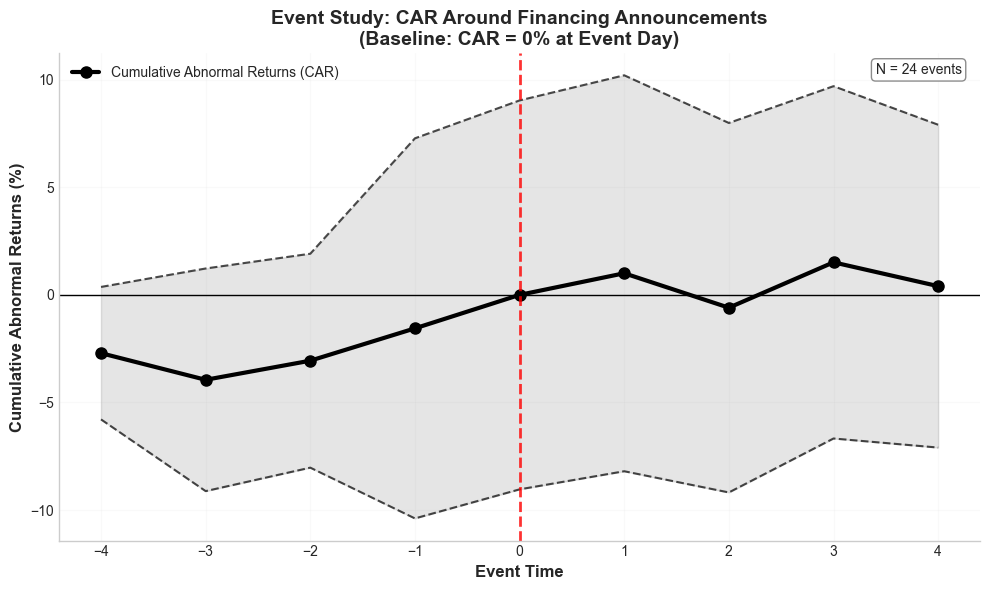

Total events analyzed: 24
Event window: t-4 to t+4 (9 biweekly periods)

Key CAR values (relative to t=0 baseline):
--------------------------------------------------
t-4      : CAR =  -2.71%
t-3      : CAR =  -3.95%
t-2      : CAR =  -3.06%
t-1      : CAR =  -1.56%
t=0 (Event) : CAR = 0.00%
t+1      : CAR =   1.00%
t+2      : CAR =  -0.60%
t+3      : CAR =   1.51%
t+4      : CAR =   0.41%
--------------------------------------------------

Average CAR before event (t-4 to t-1): -2.82%
Average CAR after event (t+1 to t+4): 0.58%
Total CAR change from t-4 to t+4: 0.41%


In [45]:
# ============================================================================
# CLASSIC STANDARD EVENT STUDY PLOT
# ============================================================================

# Aggregate data for all events
agg_all_events = event_study_car.groupBy("relative_period").agg(
    F.avg("car").alias("mean_car"),
    F.stddev("car").alias("std_car"),
    F.count("*").alias("n_observations"),
    F.countDistinct("event_ticker", "event_index").alias("n_events")
).orderBy("relative_period")

# Convert to pandas
agg_all_pdf = agg_all_events.toPandas().sort_values("relative_period")

# Reset CAR to 0 at t=0 (baseline adjustment)
if 0 in agg_all_pdf['relative_period'].values:
    car_at_t0 = agg_all_pdf[agg_all_pdf['relative_period'] == 0]['mean_car'].iloc[0]
    agg_all_pdf['mean_car_reset'] = agg_all_pdf['mean_car'] - car_at_t0
    agg_all_pdf['mean_car_plot'] = agg_all_pdf['mean_car_reset']
else:
    agg_all_pdf['mean_car_plot'] = agg_all_pdf['mean_car']

# Calculate confidence intervals (95%)
n_events = int(agg_all_pdf['n_events'].mean())
t_critical = stats.t.ppf(0.975, n_events-1) if n_events > 1 else 1.96
agg_all_pdf['ci_lower'] = agg_all_pdf['mean_car_plot'] - t_critical * (agg_all_pdf['std_car'] / np.sqrt(agg_all_pdf['n_observations']))
agg_all_pdf['ci_upper'] = agg_all_pdf['mean_car_plot'] + t_critical * (agg_all_pdf['std_car'] / np.sqrt(agg_all_pdf['n_observations']))

# Create standard event study plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot CAR line
ax.plot(agg_all_pdf['relative_period'], agg_all_pdf['mean_car_plot'] * 100,
        linewidth=3, color='black', marker='o', markersize=8,
        label='Cumulative Abnormal Returns (CAR)')

# Plot confidence intervals
ax.plot(agg_all_pdf['relative_period'], agg_all_pdf['ci_lower'] * 100,
        linewidth=1.5, color='black', linestyle='--', alpha=0.7)
ax.plot(agg_all_pdf['relative_period'], agg_all_pdf['ci_upper'] * 100,
        linewidth=1.5, color='black', linestyle='--', alpha=0.7)

# Fill confidence interval
ax.fill_between(agg_all_pdf['relative_period'],
                agg_all_pdf['ci_lower'] * 100,
                agg_all_pdf['ci_upper'] * 100,
                alpha=0.2, color='gray')

# Add event day and zero lines
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8)
ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

# Format plot
ax.set_xlabel('Event Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Abnormal Returns (%)', fontsize=12, fontweight='bold')
ax.set_title('Event Study: CAR Around Financing Announcements\n(Baseline: CAR = 0% at Event Day)', 
             fontsize=14, fontweight='bold')

ax.set_xticks(range(-4, 5))
ax.grid(True, alpha=0.1, linestyle='-')
ax.legend(loc='upper left', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add sample size
ax.text(0.98, 0.98, f'N = {n_events} events',
        transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total events analyzed: {n_events}")
print(f"Event window: t-4 to t+4 (9 biweekly periods)")

print("\nKey CAR values (relative to t=0 baseline):")
print("-" * 50)

for period in [-4, -3, -2, -1, 0, 1, 2, 3, 4]:
    if period in agg_all_pdf['relative_period'].values:
        row = agg_all_pdf[agg_all_pdf['relative_period'] == period].iloc[0]
        car_val = row['mean_car_plot'] * 100
        
        if period == 0:
            period_label = "t=0 (Event)"
            car_display = "0.00"
        elif period < 0:
            period_label = f"t{period}"
            car_display = f"{car_val:6.2f}"
        else:
            period_label = f"t+{period}"
            car_display = f"{car_val:6.2f}"
        
        print(f"{period_label:8} : CAR = {car_display}%")

print("-" * 50)

# Calculate key metrics
pre_event_avg = agg_all_pdf[agg_all_pdf['relative_period'] < 0]['mean_car_plot'].mean() * 100
post_event_avg = agg_all_pdf[agg_all_pdf['relative_period'] > 0]['mean_car_plot'].mean() * 100
total_change = agg_all_pdf[agg_all_pdf['relative_period'] == 4]['mean_car_plot'].iloc[0] * 100

print(f"\nAverage CAR before event (t-4 to t-1): {pre_event_avg:.2f}%")
print(f"Average CAR after event (t+1 to t+4): {post_event_avg:.2f}%")
print(f"Total CAR change from t-4 to t+4: {total_change:.2f}%")

In [46]:
# Interpret the CAR results
if 'mean_car_plot' in agg_all_pdf.columns:
    final_car = agg_all_pdf[agg_all_pdf['relative_period'] == 4]['mean_car_plot'].iloc[0] * 100
    
    print(f"\nTotal CAR from t-4 to t+4: {final_car:.2f}%")
    
    if final_car > 0:
        print(f"Positive market reaction to financing announcements")
        print(f"Stocks outperform market by {final_car:.2f}%")
    else:
        print(f"Negative market reaction to financing announcements")
        print(f"Stocks underperform market by {abs(final_car):.2f}%")
    
    # Check statistical significance
    t_stat = final_car/100 / (agg_all_pdf['std_car'].mean()/np.sqrt(agg_all_pdf['n_observations'].mean()))
    p_value = 2 * (1 - stats.t.cdf(np.abs(t_stat), n_events-1))
    
    if p_value < 0.05:
        print(f"Statistically significant (p = {p_value:.4f})")
    else:
        print(f"Not statistically significant (p = {p_value:.4f})")


Total CAR from t-4 to t+4: 0.41%
Positive market reaction to financing announcements
Stocks outperform market by 0.41%
Not statistically significant (p = 0.9078)


### We used another CAR calculation in our actual presentation, this was mainly a workflow test